In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import odeint
from scipy.optimize import curve_fit

# Configuração de estilo para os gráficos ficarem bonitos (Seaborn)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [9]:
def sir_model(y, t, N, beta, gamma):
    S, I, R = y
    
    # Equações diferenciais
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    
    return dSdt, dIdt, dRdt

In [10]:
# URL direto do dataset de casos confirmados (GitHub da JHU)
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"

# Carregando dados
df_raw = pd.read_csv(url)

# Filtrando para o Brasil
df_brazil = df_raw[df_raw['Country/Region'] == 'Brazil'].drop(columns=['Province/State', 'Lat', 'Long', 'Country/Region'])
df_brazil = df_brazil.T # Transpondo para ter datas nas linhas
df_brazil.columns = ['Confirmados']

# Limpeza e conversão de datas
df_brazil.index = pd.to_datetime(df_brazil.index)
df_brazil = df_brazil[df_brazil['Confirmados'] > 100] # Começar análise após 100 casos

# Criando coluna de dias passados desde o início
df_brazil['Dias'] = np.arange(len(df_brazil))

# IMPORTANTE: Vamos cortar para os primeiros 160 dias para modelar a primeira onda
# O modelo SIR simples assume imunidade constante e população fechada
dias_analise = 160
dados_focados = df_brazil.iloc[:dias_analise].copy()

# Estimativa grosseira de Ativos (Infectados) para o modelo simples
# Assumindo que I ≈ Confirmados (pois não temos dados confiáveis de recuperados diários no início)
# Para um fit perfeito, idealmente usaríamos dados de "Casos Ativos", mas usaremos "Confirmados Acumulados" como proxy da curva de crescimento
y_data = dados_focados['Confirmados'].values
x_data = dados_focados['Dias'].values
N = 214000000 # População aproximada do Brasil

print(f"Dados carregados. Analisando os primeiros {dias_analise} dias da pandemia no Brasil.")
dados_focados.head()

Dados carregados. Analisando os primeiros 160 dias da pandemia no Brasil.


C:\Users\pedro\AppData\Local\Temp\ipykernel_6052\2556429279.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_brazil.index = pd.to_datetime(df_brazil.index)


,Confirmados,Dias
2020-03-13,151,0
2020-03-14,151,1
2020-03-15,162,2
2020-03-16,200,3
2020-03-17,321,4


In [11]:
def fit_odeint(x, beta, gamma):
    # Condições iniciais
    I0 = y_data[0]
    R0 = 0
    S0 = N - I0 - R0
    y0 = S0, I0, R0
    
    # Resolver a EDO para o tempo x com os parâmetros beta e gamma dados
    ret = odeint(sir_model, y0, x, args=(N, beta, gamma))
    S, I, R = ret.T
    
    # Retornamos (I + R) porque os dados do JHU são "Confirmados Totais"
    return I + R

In [12]:
# Chute inicial para os parâmetros [beta, gamma]
parametros_iniciais = [0.2, 0.1]

# Realizando a otimização
popt, pcov = curve_fit(fit_odeint, x_data, y_data, p0=parametros_iniciais)

beta_otimo, gamma_otimo = popt

print(f"Parâmetros Otimizados Encontrados:")
print(f"Beta (Taxa de infecção): {beta_otimo:.4f}")
print(f"Gamma (Taxa de recuperação): {gamma_otimo:.4f}")

# Calculando o R0 (Número básico de reprodução)
R0_val = beta_otimo / gamma_otimo
print(f"R0 (Número Básico de Reprodução): {R0_val:.2f}")

Parâmetros Otimizados Encontrados:
Beta (Taxa de infecção): 4.7729
Gamma (Taxa de recuperação): 4.7285
R0 (Número Básico de Reprodução): 1.01


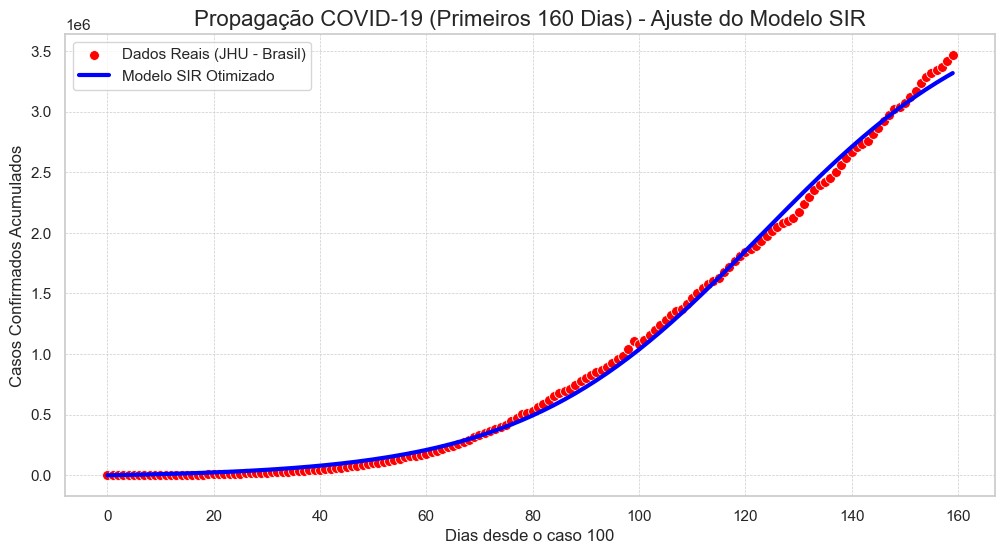

In [13]:
# Gerar a curva do modelo com os parâmetros ótimos encontrados
fitted_curve = fit_odeint(x_data, beta_otimo, gamma_otimo)

# Plotagem
plt.figure(figsize=(12, 6))

# Dados Reais
sns.scatterplot(x=x_data, y=y_data, color='red', label='Dados Reais (JHU - Brasil)', s=50)

# Modelo Matemático Ajustado
sns.lineplot(x=x_data, y=fitted_curve, color='blue', label='Modelo SIR Otimizado', linewidth=3)

plt.title(f'Propagação COVID-19 (Primeiros {dias_analise} Dias) - Ajuste do Modelo SIR', fontsize=16)
plt.xlabel('Dias desde o caso 100', fontsize=12)
plt.ylabel('Casos Confirmados Acumulados', fontsize=12)
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)

plt.show()

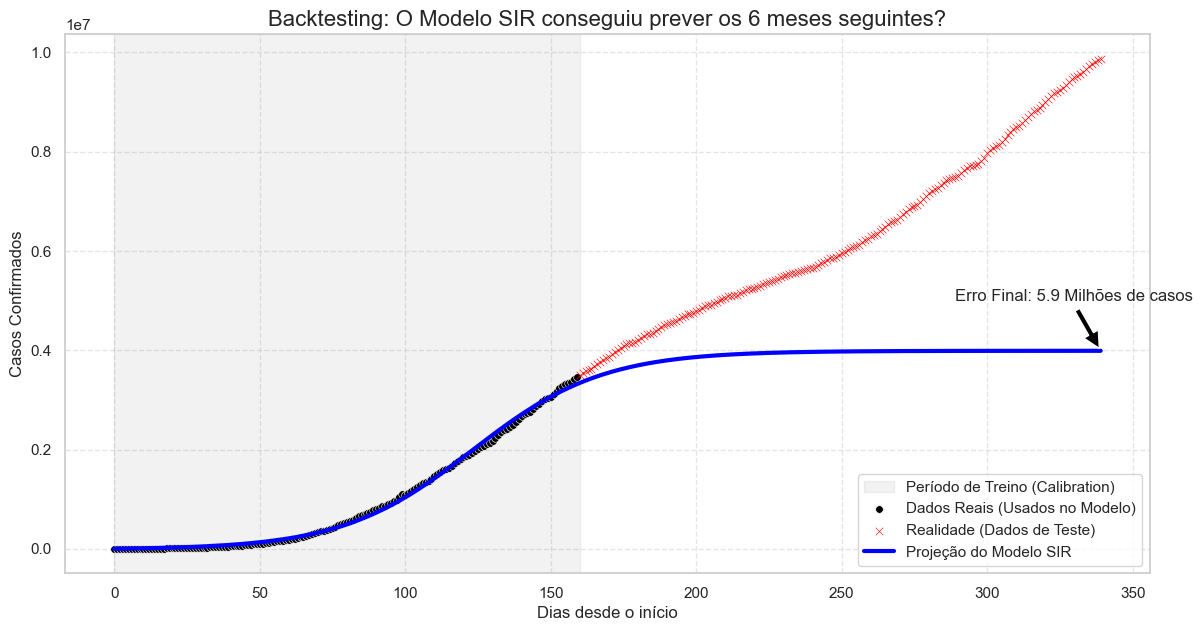

In [ ]:
# Projetar para mais 50 dias além dos dados
t_futuro = np.arange(len(x_data) + 50)
projecao = fit_odeint(t_futuro, beta_otimo, gamma_otimo)

plt.figure(figsize=(12, 6))
plt.plot(t_futuro, projecao, label='Projeção do Modelo SIR')
plt.axvline(x=len(x_data), color='k', linestyle='--', label='Fim dos dados reais')
plt.title('Projeção da Curva Teórica')
plt.xlabel('Dias')
plt.ylabel('Casos Acumulados')
plt.legend()
plt.show()